<a href="https://colab.research.google.com/github/Shanmugapriya85/sprint4_final_project_starter.ipynb/blob/main/sprint4_final_project_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sprint 4 Project: E-Commerce Customer Behavior EDA

Welcome to your Sprint 4 final project. In this project, you will apply everything you've learned across Sprints 1–4 to perform a complete Exploratory Data Analysis on the **Olist Brazilian E-Commerce dataset** — real data from a real e-commerce platform.


## Dataset

You'll work with 7 CSV files from the Olist e-commerce dataset:

| File | Rows | Description |
|---|---|---|
| `olist_orders_dataset.csv` | 99,441 | Orders with timestamps and status |
| `olist_order_items_dataset.csv` | 112,650 | Items per order with price and freight |
| `olist_customers_dataset.csv` | 99,441 | Customer ID, city, state |
| `olist_products_dataset.csv` | 32,951 | Products with category and dimensions |
| `olist_order_reviews_dataset.csv` | 99,224 | Review scores (1–5 stars) |
| `olist_order_payments_dataset.csv` | 103,886 | Payment type and value |
| `product_category_name_translation.csv` | 71 | Portuguese → English category names |

Let's get started!

---

## Setup

Run the cells below to import the libraries you'll need and load the datasets. The data is hosted on GitHub, so you can load it with one line of code per file — no uploads required.

In [ ]:
# Import libraries
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Confirm versions
print(f"pandas version: {pd.__version__}")
print("Setup complete!")

pandas version: 2.2.3
Setup complete!


In [ ]:
# Load the 7 datasets from the curriculum GitHub repo
BASE_URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analytics/eda-project/'

orders = pd.read_csv(BASE_URL + 'olist_orders_dataset.csv')
items = pd.read_csv(BASE_URL + 'olist_order_items_dataset.csv')
customers = pd.read_csv(BASE_URL + 'olist_customers_dataset.csv')
products = pd.read_csv(BASE_URL + 'olist_products_dataset.csv')
reviews = pd.read_csv(BASE_URL + 'olist_order_reviews_dataset.csv')
payments = pd.read_csv(BASE_URL + 'olist_order_payments_dataset.csv')
translation = pd.read_csv(BASE_URL + 'product_category_name_translation.csv')

print(f"orders:      {orders.shape}")
print(f"items:       {items.shape}")
print(f"customers:   {customers.shape}")
print(f"products:    {products.shape}")
print(f"reviews:     {reviews.shape}")
print(f"payments:    {payments.shape}")
print(f"translation: {translation.shape}")

orders:      (99441, 8)
items:       (112650, 7)
customers:   (99441, 5)
products:    (32951, 9)
reviews:     (99224, 7)
payments:    (103886, 5)
translation: (71, 2)


In [ ]:
# Set up an in-memory SQLite database with all 7 tables
# This lets you run SQL queries directly against the DataFrames
conn = sqlite3.connect(':memory:')

orders.to_sql('orders', conn, index=False, if_exists='replace')
items.to_sql('items', conn, index=False, if_exists='replace')
customers.to_sql('customers', conn, index=False, if_exists='replace')
products.to_sql('products', conn, index=False, if_exists='replace')
reviews.to_sql('reviews', conn, index=False, if_exists='replace')
payments.to_sql('payments', conn, index=False, if_exists='replace')
translation.to_sql('translation', conn, index=False, if_exists='replace')

print("SQLite database ready. You can now run SQL queries with pd.read_sql().")

SQLite database ready. You can now run SQL queries with pd.read_sql().


---

## Question 1: Inspect the orders DataFrame

**Your task:** For the `orders` DataFrame:
1. Print its shape
2. Print the first 5 rows with `.head()`
3. Print column info with `.info()`

This is the very first thing every analyst does with a new dataset.

*Skills: Sprint 4 Ch 01 (Pandas inspection)*

In [ ]:
#  Inspect the orders DataFrame
print(orders.shape)
print(orders.head())
print(orders.info())


(99441, 8)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00       

---

## Question 2: Clean the orders data

The `orders` DataFrame has timestamp columns stored as strings, and a few have missing values.

**Your task:**
1. Use `.isnull().sum()` to count missing values in each column of `orders`
2. Convert `order_purchase_timestamp` and `order_delivered_customer_date` to datetime using `pd.to_datetime()`
3. Print the dtypes after conversion to verify

*Skills: Sprint 4 Ch 02 (Cleaning, dtype conversion)*

In [ ]:
# Clean the orders data
print(orders.isnull().sum())
# data type conversion
orders['order_purchase_timestamp']=pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date']= pd.to_datetime(orders['order_delivered_customer_date'])
print(orders.dtypes)

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                        object
order_delivered_carrier_date             object
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date            object
dtype: object


---

## Question 3: Order status breakdown (SQL)

**Your task:** Write a SQL query against the `orders` table that returns:
- `order_status`
- `num_orders` — count of orders with that status
- `pct` — percentage of total orders, rounded to 2 decimals

Sort by `num_orders` descending. Save the result to a DataFrame called `status_summary` and print it.

**Hint:** Use `pd.read_sql("...", conn)`. The percentage trick is `COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders)`.

*Skills: Sprint 2 (SQL aggregation), Sprint 4 Ch 03 (Descriptive stats)*

In [ ]:
# SQL query
status_summary = pd.read_sql("""
    SELECT
      order_status,
      count(*) AS num_orders,
      Round(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders),2 ) AS pct
    From Orders
    GROUP BY order_status
    ORDER BY num_orders DESC
     """  , conn
)
print(status_summary)


  order_status  num_orders    pct
0    delivered       96478  97.02
1      shipped        1107   1.11
2     canceled         625   0.63
3  unavailable         609   0.61
4     invoiced         314   0.32
5   processing         301   0.30
6      created           5   0.01
7     approved           2   0.00


---

## Question 4: Top 10 highest-revenue orders (SQL JOIN)

Each order can have multiple items. Total order revenue = sum of `price + freight_value` across all its items.

**Your task:** Write a SQL query that JOINs `orders` and `items` to find the **10 highest-revenue orders**. Return:
- `order_id`
- `order_status`
- `total_revenue` — rounded to 2 decimals

Save the result to `top_orders` and print it.

*Skills: Sprint 2 (SQL JOIN, GROUP BY), Sprint 4 Ch 06 (combining tables)*

In [ ]:

top_orders = pd.read_sql("""
  SELECT
   o.order_id,
   o.order_status,
    ROUND(SUM(i.price+i.freight_value),2) As total_revenue
  FROM orders AS o

  INNER JOIN items AS i
    ON o.order_id = i.order_id

  GROUP BY o.order_id,o.order_status

  ORDER BY total_revenue DESC

  LIMIT 10

""",conn)

print(top_orders)


                           order_id order_status  total_revenue
0  03caa2c082116e1d31e67e9ae3700499    delivered       13664.08
1  736e1922ae60d0d6a89247b851902527    delivered        7274.88
2  0812eb902a67711a1cb742b3cdaa65ae    delivered        6929.31
3  fefacc66af859508bf1a7934eab1e97f    delivered        6922.21
4  f5136e38d1a14a4dbd87dff67da82701    delivered        6726.66
5  2cc9089445046817a7539d90805e6e5a    delivered        6081.54
6  a96610ab360d42a2e5335a3998b4718a    delivered        4950.34
7  b4c4b76c642808cbe472a32b86cddc95     canceled        4809.44
8  199af31afc78c699f0dbf71fb178d4d4    delivered        4764.34
9  8dbc85d1447242f3b127dda390d56e19    delivered        4681.78


---

## Question 5: English product categories (pandas merge)

The `products` table has a Portuguese category column called `product_category_name`. The `translation` table maps each Portuguese name to its English equivalent.

**Your task:**
1. Use `products.merge(translation, on='product_category_name', how='left')` to add the English column. Save it to `products_eng`.
2. Find the **top 10 categories by number of products** using `value_counts()` on the `product_category_name_english` column. Save to `top_categories` and print it.

*Skills: Sprint 4 Ch 06 (pandas merge), Ch 03 (value_counts)*

In [ ]:
products_eng = products.merge(translation, on='product_category_name', how='left')
top_categories = products_eng['product_category_name_english'].value_counts().head(10)


print(top_categories)


product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64



## Question 6: Revenue and average review score by category

Now you'll combine three tables and compute multiple metrics per category.

**Your task:**
1. Build a DataFrame that merges `items` with `products_eng` (to get categories), then merges with `reviews` (to get scores). The shared key chain is: `items.product_id → products_eng.product_id` and `items.order_id → reviews.order_id`.
2. Add a `revenue` column = `price + freight_value`
3. Group by `product_category_name_english` and aggregate:
   - `total_revenue` = sum of `revenue`
   - `avg_review` = mean of `review_score`
   - `n_items` = count of `order_id`
4. Sort by `total_revenue` descending and show the **top 10 categories**. Save to `category_summary`.

*Skills: Sprint 4 Ch 06 (multi-table merge, groupby with multiple aggregations)*

In [ ]:
products_eng = products.merge(translation, on ='product_category_name',how='left')

items_with_categories = items.merge(products_eng, on ='product_id', how ='left')

reviews_orders = items_with_categories.merge(reviews,on='order_id',how ='left')

print(reviews_orders.columns)

reviews_orders['revenue'] = reviews_orders['price'] + reviews_orders['freight_value']

category_summary = reviews_orders.groupby(
        'product_category_name_english'
).agg(
   total_revenue = ('revenue','sum'),
   avg_review =('review_score','mean'),
   n_items=('order_id','count')
)

category_summary = category_summary.sort_values('total_revenue',ascending=False).head(10)

print(category_summary)


Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'product_category_name_english', 'review_id', 'review_score',
       'review_comment_title', 'review_comment_message',
       'review_creation_date', 'review_answer_timestamp'],
      dtype='object')
                               total_revenue  avg_review  n_items
product_category_name_english                                    
health_beauty                     1446622.08    4.142768     9727
watches_gifts                     1306761.40    4.019160     6001
bed_bath_table                    1258189.51    3.895663    11270
sports_leisure                    1163329.98    4.107986     8700
computers_accessories             1068070.48    3.930819     7894
furniture

---

## Question 7: Top 10 customer states (SQL + bar chart)

**Your task:**
1. Write a SQL query that returns the **top 10 customer states** by number of customers. Columns: `customer_state`, `num_customers`. Save to `state_top10`.
2. Create a **bar chart** of `num_customers` by `customer_state`. Add a title and rotate the x-tick labels if they overlap.

*Skills: Sprint 2 (SQL GROUP BY), Sprint 4 Ch 04 (bar chart)*

  customer_state  num_customers
0             SP          41746
1             RJ          12852
2             MG          11635
3             RS           5466
4             PR           5045
5             SC           3637
6             BA           3380
7             DF           2140
8             ES           2033
9             GO           2020


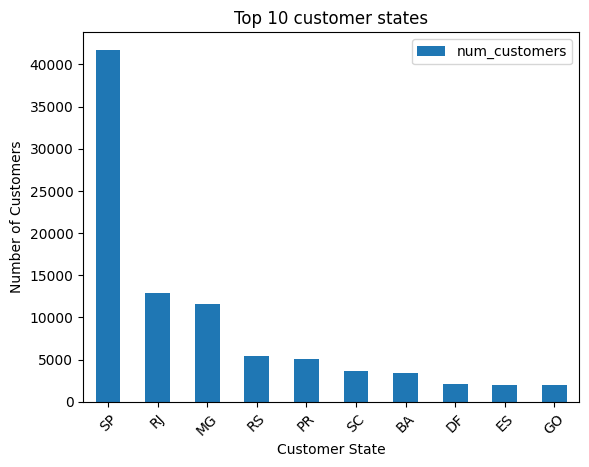

In [ ]:
state_top10 = pd.read_sql("""
  SELECT
     customer_state,
     COUNT(*) AS num_customers
  FROM customers

  GROUP BY customer_state
  ORDER BY num_customers DESC
  LIMIT 10
""",conn)

print(state_top10)

state_top10.plot(
    kind='bar',
    x='customer_state',
    y='num_customers',
    xlabel='Customer State',
    ylabel='Number of Customers',
    title='Top 10 customer states',
    rot=45
)
plt.show()


---

## Question 8: Monthly order trend (line chart)

**Your task:**
1. From the cleaned `orders` DataFrame (with datetime columns from Q2), extract a `year_month` period from `order_purchase_timestamp` using `.dt.to_period('M')`
2. Count orders per month — save to a DataFrame called `monthly_orders` with columns `year_month` and `num_orders`
3. Plot a **line chart** of `num_orders` over time. Add a title.

**Hint:** `orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()` is a fast way to get monthly counts. Convert the period index back to string for plotting.

*Skills: Sprint 4 Ch 02 (datetime), Ch 03 (groupby), Ch 04 (line chart)*

  order_purchase_timestamp year_month
0      2017-10-02 10:56:33    2017-10
1      2018-07-24 20:41:37    2018-07
2      2018-08-08 08:38:49    2018-08
3      2017-11-18 19:28:06    2017-11
4      2018-02-13 21:18:39    2018-02
  year_month  num_orders
0    2016-09           4
1    2016-10         324
2    2016-12           1
3    2017-01         800
4    2017-02        1780


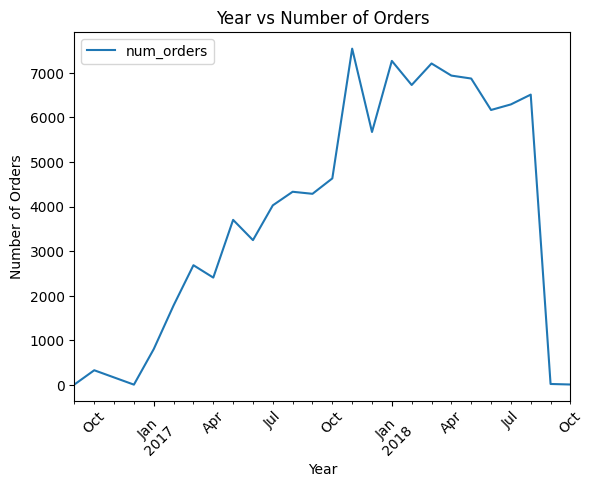

In [ ]:
#orders['order_purchase_timestamp']=pd.to_datetime(orders['order_purchase_timestamp'])
orders['year_month'] = orders['order_purchase_timestamp'].dt.to_period('M')

print(orders[['order_purchase_timestamp', 'year_month']].head())

monthly_orders = orders.groupby('year_month').size().reset_index(name='num_orders')
print(monthly_orders.head())

monthly_orders.plot(
    kind='line',
    x='year_month',
    y='num_orders',
    xlabel='Year',
    ylabel='Number of Orders',
    title='Year vs Number of Orders',
    rot=45
)
plt.show()


---

## Question 9: Does delivery speed affect review scores?

This is a real business question: do customers who get their orders faster leave better reviews?

**Your task:**
1. From `orders`, keep only rows where `order_delivered_customer_date` is not null
2. Add a `delivery_days` column = (delivery date − purchase date) in days. **Hint:** subtract the two datetime columns and use `.dt.days`
3. Merge with `reviews` on `order_id` to get the `review_score` for each order
4. Compute the **correlation** between `delivery_days` and `review_score` using `.corr()`
5. Group by `review_score` and show the **average delivery days** for each score (1 through 5)
6. Plot a bar chart of average delivery days by review score

What pattern do you see? Add a markdown cell with your interpretation.

*Skills: Sprint 4 Ch 03 (correlation), Ch 04 (visualization), Ch 06 (merge + groupby)*

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   
5  a4591c265e18cb1dcee52889e2d8acc3  503740e9ca751ccdda7ba28e9ab8f608   
6  6514b8ad8028c9f2cc2374ded245783f  9bdf08b4b3b52b5526ff42d37d47f222   
7  76c6e866289321a7c93b82b54852dc33  f54a9f0e6b351c431402b8461ea51999   
8  e69bfb5eb88e0ed6a785585b27e16dbf  31ad1d1b63eb9962463f764d4e6e0c9d   
9  e6ce16cb79ec1d90b1da9085a6118aeb  494dded5b201313c64ed7f100595b95c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2   

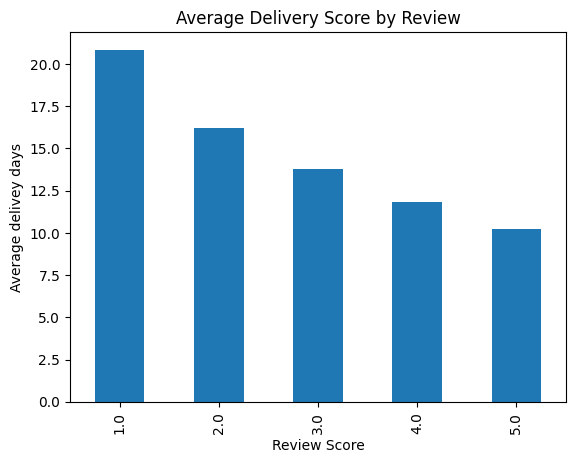

In [ ]:
# 1.Delivered order Not Null
delivered_orders = orders[orders['order_delivered_customer_date'].notna()].copy()

#print(delivered_orders.head())

#2.Order delivered in how many day

delivered_orders['order_delivered_customer_date'] = pd.to_datetime(delivered_orders['order_delivered_customer_date'])
delivered_orders['order_purchase_timestamp'] = pd.to_datetime( delivered_orders['order_purchase_timestamp'])

delivered_orders['delivery_days'] = (
    delivered_orders['order_delivered_customer_date']
    - delivered_orders['order_purchase_timestamp']
).dt.days

#3.To get the customer review score for each order

delivered_reviews =delivered_orders.merge(reviews[['order_id', 'review_score']],on='order_id',how = 'left')

print(delivered_reviews.head(10))

#4.correlation

correlation = delivered_reviews['delivery_days'].corr(
    delivered_reviews['review_score']
)

print(correlation)

# creating chart by calculating the average delivery
avg_delivery = delivered_reviews.groupby('review_score')['delivery_days'].mean()

avg_delivery.plot(
    kind='bar',
    xlabel='Review Score',
    ylabel='Average delivey days',
    title='Average Delivery Score by Review'
    )
plt.show()


The correlation coefficient of -0.33 indicates a moderate negative relationship between delivery time and customer review scores. The bar chart supports this finding, showing that orders with longer delivery times tend to receive lower ratings, with 1-star reviews having the highest average delivery duration.

This suggests that longer delivery times may be associated with lower customer satisfaction.

Business insight: Reducing delivery times may help improve customer satisfaction.

---

## Question 10: Final Report

Write a **2–3 paragraph executive summary** of your findings as a markdown cell below. A good report answers:

- **What is the overall health of the business?** (Use Q3, Q8 — order volumes and trends)
- **Which product categories should we double down on?** (Use Q6 — revenue + review scores together)
- **Where are our customers and how do we serve them?** (Use Q7, Q9 — geography and delivery speed)
- **What is one specific recommendation you would make to the leadership team?**

Write as if you're presenting to a non-technical executive. Use plain language. Reference specific numbers from your analysis.

*Skills: Sprint 4 Ch 06 (analytical reporting)*

Executive Summary

Business Health
Olist's overall business performance appears positive, with strong order fulfillment and growing customer demand. Based on the Q3 analysis, 97.02% of orders (96,478) were successfully delivered, while only 0.63% (625 orders) were canceled and 0.61% were unavailable. The high delivery rate and low cancellation rate indicate efficient order fulfillment.

Monthly order volumes increased significantly throughout 2017, reaching approximately 7,500 orders at their peak. Order volumes remained relatively high during much of 2018, indicating sustained customer demand. The sharp decline at the end of the reporting period may be due to incomplete data and requires further investigation.

Top Categories

Health & Beauty, Watches & Gifts, and Bed, Bath & Table were the top three product categories by revenue. Health & Beauty generated the highest revenue of approximately R$1.45 million, with an average review score of 4.14. Watches & Gifts generated R$1.31 million with an average review score of 4.02, followed by Bed, Bath & Table at R$1.26 million with a score of 3.90.

Although Bed, Bath & Table had the highest number of items sold (11,270) among the top 10 categories, its relatively lower review score indicates an opportunity to investigate and improve customer satisfaction. Sports & Leisure also performed well, generating R$1.16 million with an average review score of 4.11.

Health & Beauty and Sports & Leisure demonstrate a strong combination of revenue performance and customer satisfaction, making them promising categories for future investment.

Customer Geography & Delivery

The majority of customers were concentrated in São Paulo (41,746), Rio de Janeiro (12,852), and Minas Gerais (11,635). These states represent important markets for Olist's business operations. Delivery analysis showed a moderate negative correlation of -0.33 between delivery days and customer review scores. The bar chart also showed that customers giving 1-star reviews experienced the longest average delivery times. This suggests that longer delivery times are associated with lower customer satisfaction.

Recommendation

I recommend that Olist focus on improving delivery speed in high-demand states, particularly São Paulo, Rio de Janeiro, and Minas Gerais. The company should work with logistics partners to reduce delivery delays and improve delivery efficiency. Faster and more reliable deliveries may improve customer satisfaction and encourage repeat purchases. Olist should also continue investing in product categories that generate high revenue and receive positive customer reviews.
